# Random forest classification

Compare a single tree with a random forest and review feature importance.

**Dataset:** `data/student_data.csv` (395 student records, 33 columns). **Target:** final grade `G3` (0–20). For classification labs, pass means `G3 ≥ 10`. Earlier grades `G1` and `G2` are included as predictors; interpret results as prediction after those earlier grades are known. The split is fixed with random seed 42 for reproducibility.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATHS = [Path("data/student_data.csv"), Path("../data/student_data.csv")]
DATA_PATH = next((p for p in DATA_PATHS if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place student_data.csv in the repository's data/ folder.")
df = pd.read_csv(DATA_PATH)
TARGET = "G3"  # final-period grade (0–20)
PASS_THRESHOLD = 10
numeric_features = df.select_dtypes(include=np.number).columns.drop(TARGET).tolist()
categorical_features = df.select_dtypes(exclude=np.number).columns.tolist()
feature_cols = numeric_features + categorical_features
X = df[feature_cols]
y_reg = df[TARGET]
y_class = (df[TARGET] >= PASS_THRESHOLD).astype(int)


In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

def make_preprocessor(scale_numeric=True):
    numeric_steps = [("scale", StandardScaler())] if scale_numeric else []
    numeric_pipe = Pipeline(numeric_steps) if numeric_steps else "passthrough"
    return ColumnTransformer(
        [("numeric", numeric_pipe, numeric_features),
         ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)],
        remainder="drop",
    )


,model,accuracy,macro_f1
0,Decision tree,0.838384,0.830769
1,Random forest,0.868687,0.860488


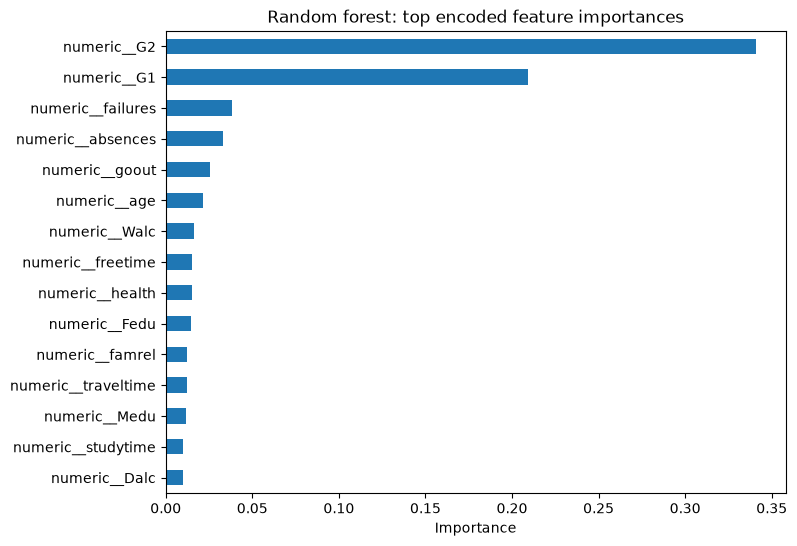

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

X_train, X_test, y_train, y_test = train_test_split(X, y_class, test_size=0.25, stratify=y_class, random_state=42)
rows=[]
for name, clf in [("Decision tree", DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42)),
                  ("Random forest", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42))]:
    pipe=Pipeline([("preprocess", make_preprocessor(scale_numeric=False)), ("classifier", clf)])
    pipe.fit(X_train,y_train); p=pipe.predict(X_test)
    rows.append({"model":name,"accuracy":accuracy_score(y_test,p),"macro_f1":f1_score(y_test,p,average="macro")})
display(pd.DataFrame(rows))
rf=Pipeline([("preprocess",make_preprocessor(scale_numeric=False)),("classifier",RandomForestClassifier(n_estimators=300,class_weight="balanced",random_state=42))])
rf.fit(X_train,y_train)
names=rf.named_steps["preprocess"].get_feature_names_out()
imp=pd.Series(rf.named_steps["classifier"].feature_importances_,index=names).nlargest(15).sort_values()
imp.plot.barh(figsize=(8,6),title="Random forest: top encoded feature importances")
plt.xlabel("Importance"); plt.show()
